In [1]:
import nltk
nltk.download('stopwords')
nltk.download('snowball_data')

[nltk_data] Downloading package stopwords to /home/camilo-
[nltk_data]     omarchy/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package snowball_data to /home/camilo-
[nltk_data]     omarchy/nltk_data...


True

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, SnowballStemmer
from nltk.tokenize import TweetTokenizer

import re
import string

import itertools

In [3]:
datos_raw = pd.read_csv("datos_salud_mental.csv")

In [4]:
datos_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 31755 entries, 0 to 31754
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   status           31755 non-null  str  
 1   statement_es_es  31755 non-null  str  
dtypes: str(2)
memory usage: 496.3 KB


In [5]:
def create_numeric_status(df):
    df['numeric_status'] = df['status'].apply(lambda x: 1 if x == 'Normal' else 0)
    return df

In [6]:
datos = create_numeric_status(datos_raw.copy())
datos.head()

,status,statement_es_es,numeric_status
0,Normal,Gr gr soñando con el ex crush para que sea mi ...,1
1,Normal,wkwkwk qué broma,1
2,Normal,Las hojas también están de espera frente al PC...,1
3,Normal,Gracias a Dios aunque sea un viaje en coche,1
4,Normal,teaser de boda concepto utilizando la canción ...,1


In [7]:
datos["statement_es_es"][20:50].to_list()

['chat.',
 'Mi hermana parece cansada de oírte tocar sunlit smile',
 'Motocicleta otra vez jaja',
 'Espero que la fuerza de mi hermano no se vaya a los niños.',
 'por suerte, el póster del álbum.',
 '¿Cómo estás?',
 'Sí cariño, hemos ganado.',
 "Esta mañana huele muy bien:'",
 '¿Por qué esta persona dice cosas sobre carros de compras blah blah blah. si se le da, ¿lo quieres a él o no?',
 'Limpiar la habitación',
 '¿Cómo estás amigo?',
 'Antes de que salga el vídeo musical de nct dream hot sauce, ¡vamos a ser mejores amigas!',
 'Siempre habrá tai. Así que no es solo bonito.',
 'Quiero tomarme un día libre del trabajo y luego llevarla a dar un largo paseo.',
 'ni-ki ¿por qué? Acabo de abrir twt.',
 'Este lunes ha sido muchas veces más lento de lo habitual. ¡damn it!',
 'Eres adicto que me hace dudar.',
 '¿Cuántos billetes de bbl hay ahora? ¿Por qué quiero suscribirme pero dice que mi crédito no funciona aunque mi crédito sea de 70 mil?',
 '¿A alguien le han llegado zapatos co shpe 5.5 to

In [8]:
# Apply the function to create the numeric_status column
datos = create_numeric_status(datos.copy())

y = datos["numeric_status"]
X = datos.drop(["status", "numeric_status"], axis=1)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,       # 20% for testing, 80% for training
    random_state=271828, # Mismo split que topic_model.ipynb (LSA / LDiA)
    shuffle=True         # Shuffles data before splitting
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (25404, 1)
X_test shape: (6351, 1)
y_train shape: (25404,)
y_test shape: (6351,)


In [10]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 25404 entries, 15415 to 2178
Data columns (total 1 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   statement_es_es  25404 non-null  str  
dtypes: str(1)
memory usage: 396.9 KB


In [11]:
def process_tweet(tweet):
    '''
    Input:
        tweet: a string containing a tweet
    Output:
        tweets_clean: a list of words containing the processed tweet

    '''
    stemmer = SnowballStemmer("spanish")
    stopwords_spanish = stopwords.words('spanish')
    # remove stock market tickers like $GE
    tweet = re.sub(r'\$\w*', '', tweet)
    # remove old style retweet text "RT"
    tweet = re.sub(r'^RT[\s]+', '', tweet)
    # remove hyperlinks
    #tweet = re.sub(r'https?://.*[\r\n]*', '', tweet)
    tweet = re.sub(r'https?://[^\s\n\r]+', '', tweet)
    # remove hashtags
    # only removing the hash # sign from the word
    tweet = re.sub(r'#', '', tweet)
    # tokenize tweets
    tokenizer = TweetTokenizer(preserve_case=False, strip_handles=True,
                               reduce_len=True)
    tweet_tokens = tokenizer.tokenize(tweet)

    tweets_clean = []
    for word in tweet_tokens:
        if (word not in stopwords_spanish and  # remove stopwords
            word not in string.punctuation):  # remove punctuation
            #tweets_clean.append(word)
            stem_word = stemmer.stem(word)  # stemming word
            tweets_clean.append(stem_word)

    return tweets_clean

In [12]:
def count_tweets(result, tweets, ys):
  for y, tweet in zip(ys, tweets):
    for word in process_tweet(tweet):

      pair = (word, y)

      if pair in result:
        result[pair] += 1
      else:
        result[pair] = 1

  return result

In [13]:
#Probar la función
result = {}
tweets = ['estoy feliz', 'me han engañado', 'estoy triste', 'estoy cansado', 'estoy cansado']
ys = [1, 0, 0, 0, 0]
count_tweets(result, tweets, ys)

{('feliz', 1): 1, ('engañ', 0): 1, ('trist', 0): 1, ('cans', 0): 2}

In [14]:
freq = count_tweets({}, X_train["statement_es_es"], y_train)

In [15]:
type(freq)

dict

In [16]:
first_n = dict(itertools.islice(freq.items(), 10))
print(first_n)

{('favor', 0): 693, ('dam', 0): 39, ('ide', 0): 599, ('hac', 0): 12706, ('apart', 0): 217, ('jueg', 0): 410, ('videojueg', 0): 279, ('rechaz', 0): 257, ('reunion', 0): 74, ('social', 0): 875}


In [17]:
def lookup(freqs, word, label):
    '''
    Input:
        freqs: a dictionary with the frequency of each pair (or tuple)
        word: the word to look up
        label: the label corresponding to the word
    Output:
        n: the number of times the word with its corresponding label appears.
    '''
    n = 0  # freqs.get((word, label), 0)

    pair = (word, label)
    if (pair in freqs):
        n = freqs[pair]

    return n

## Explicación para tener un naive bayes

Naive bayes is an algorithm that could be used for sentiment analysis. It takes a short time to train and also has a short prediction time.

- The first part of training a naive bayes classifier is to identify the number of classes that you have.
- The second part are the probabilities,
$P(D_{pos})$ is the probability that the document is positive.
$P(D_{neg})$ is the probability that the document is negative.
Use the formulas as follows and store the values in a dictionary:

$$P(D_{pos}) = \frac{D_{pos}}{D}\tag{1}$$

$$P(D_{neg}) = \frac{D_{neg}}{D}\tag{2}$$

Where $D$ is the total number of documents, or tweets in this case, $D_{pos}$ is the total number of positive tweets and $D_{neg}$ is the total number of negative tweets.

#### Prior and Logprior

The prior probability represents the underlying probability in the target population that a tweet is positive versus negative.  In other words, if we had no specific information and blindly picked a tweet out of the population set, what is the probability that it will be positive versus that it will be negative? That is the "prior".

The prior is the ratio of the probabilities $\frac{P(D_{pos})}{P(D_{neg})}$.
We can take the log of the prior to rescale it, and we'll call this the logprior

$$\text{logprior} = log \left( \frac{P(D_{pos})}{P(D_{neg})} \right) = log \left( \frac{D_{pos}}{D_{neg}} \right)$$.

Note that $log(\frac{A}{B})$ is the same as $log(A) - log(B)$.  So the logprior can also be calculated as the difference between two logs:

$$\text{logprior} = \log (P(D_{pos})) - \log (P(D_{neg})) = \log (D_{pos}) - \log (D_{neg})\tag{3}$$

#### Positive and Negative Probability of a Word
To compute the positive probability and the negative probability for a specific word in the vocabulary, we'll use the following inputs:

- $freq_{pos}$ and $freq_{neg}$ are the frequencies of that specific word in the positive or negative class. In other words, the positive frequency of a word is the number of times the word is counted with the label of 1.
- $N_{pos}$ and $N_{neg}$ are the total number of positive and negative words for all documents (for all tweets), respectively.
- $V$ is the number of unique words in the entire set of documents, for all classes, whether positive or negative.

We'll use these to compute the positive and negative probability for a specific word using this formula:

$$ P(W_{pos}) = \frac{freq_{pos} + 1}{N_{pos} + V}\tag{4} $$
$$ P(W_{neg}) = \frac{freq_{neg} + 1}{N_{neg} + V}\tag{5} $$

Notice that we add the "+1" in the numerator for additive smoothing.

#### Log likelihood
To compute the loglikelihood of that very same word, we can implement the following equations:

$$\text{loglikelihood} = \log \left(\frac{P(W_{pos})}{P(W_{neg})} \right)\tag{6}$$

In [18]:
def train_naive_bayes(freqs, train_x, train_y):
    '''
    Input:
        freqs: dictionary from (word, label) to how often the word appears
        train_x: a list of tweets
        train_y: a list of labels corresponding to the tweets (0,1)
    Output:
        logprior: the log prior.
        loglikelihood: the log likelihood of you Naive bayes equation.
    '''
    loglikelihood = {}
    logprior = 0

    # calculate V, the number of unique words in the vocabulary
    vocab = set(key[0] for key in freqs.keys())
    V = len(vocab)

    # calculate N_pos, N_neg, V_pos, V_neg
    N_pos = N_neg = 0
    for pair in freqs.keys():
        # if the label is positive (Normal, label 1)
        if pair[1] > 0:

            # Increment the number of positive words by the count for this (word, label) pair
            N_pos += freqs[pair]

        # else, the label is negative (Depression, label 0)
        else:

            # increment the number of negative words by the count for this (word,label) pair
            N_neg += freqs[pair]

    # Calculate D, the number of documents
    D = len(train_y)

    # Calculate D_pos, the number of positive documents (Normal = 1)
    D_pos = int((train_y == 1).sum())

    # Calculate D_neg, the number of negative documents (Depression = 0)
    D_neg = int((train_y == 0).sum())

    # Calculate logprior
    logprior = np.log(D_pos) - np.log(D_neg)

    # For each word in the vocabulary...
    for word in vocab:
        # get the positive and negative frequency of the word
        freq_pos = lookup(freqs, word, 1)
        #print("look positive {}".format(freq_pos))
        freq_neg = lookup(freqs, word, 0)

        # calculate the probability that each word is positive, and negative
        p_w_pos = (freq_pos + 1) / (N_pos + V)
        p_w_neg = (freq_neg + 1) / (N_neg + V)

        # calculate the log likelihood of the word
        loglikelihood[word] = np.log(p_w_pos / p_w_neg)

    return logprior, loglikelihood


In [19]:
logprior, loglikelihood = train_naive_bayes(freq, X_train["statement_es_es"], y_train)
print(logprior)
print(len(loglikelihood))

0.05669917158158988
23248


In [20]:
def naive_bayes_predict(tweet, logprior, loglikelihood):
    '''
    Input:
        tweet: a string
        logprior: a number
        loglikelihood: a dictionary of words mapping to numbers
    Output:
        p: the sum of all the logliklihoods of each word in the tweet (if found in the dictionary) + logprior (a number)

    '''
    # process the tweet to get a list of words
    word_l = process_tweet(tweet)

    # initialize probability to zero
    p = 0

    # add the logprior
    p += logprior

    for word in word_l:

        # check if the word exists in the loglikelihood dictionary
        if word in loglikelihood:
            # add the log likelihood of that word to the probability
            p += loglikelihood[word]

    return p

In [21]:
my_tweet = 'Ella esta cantando.'
p = naive_bayes_predict(my_tweet, logprior, loglikelihood)
print('The expected output is', p)

The expected output is 1.280190717300109


In [22]:
my_tweet = 'Ella Sonrie.'
p = naive_bayes_predict(my_tweet, logprior, loglikelihood)
print('The expected output is', p)

The expected output is -0.03353295098494628


In [23]:
my_tweet = 'Ella esta wa.'
p = naive_bayes_predict(my_tweet, logprior, loglikelihood)
print('The expected output is', p)

The expected output is 3.8704578827459355


In [24]:
def test_naive_bayes(test_x, test_y, logprior, loglikelihood, naive_bayes_predict=naive_bayes_predict):
    """
    Input:
        test_x: A list of tweets
        test_y: the corresponding labels for the list of tweets
        logprior: the logprior
        loglikelihood: a dictionary with the loglikelihoods for each word
    Output:
        accuracy: (# of tweets classified correctly)/(total # of tweets)
    """
    accuracy = 0  # return this properly

    y_hats = []
    for tweet in test_x:
        # if the prediction is > 0
        if naive_bayes_predict(tweet, logprior, loglikelihood) > 0:
            # the predicted class is 1
            y_hat_i = 1
        else:
            # otherwise the predicted class is 0
            y_hat_i = 0

        # append the predicted class to the list y_hats
        y_hats.append(y_hat_i)

    # error is the average of the absolute values of the differences between y_hats and test_y
    error = np.mean(np.absolute(np.array(y_hats) - np.asarray(test_y)))

    # Accuracy is 1 minus the error
    accuracy = 1 - error

    return accuracy

In [25]:
print("Naive Bayes accuracy = %0.4f" %
      (test_naive_bayes(X_test["statement_es_es"], y_test, logprior, loglikelihood)))

Naive Bayes accuracy = 0.8238


## Métricas completas del Bayes ingenuo

Además del accuracy calculamos precision, recall y F1 (clase positiva = `Normal`, 1) con el mismo formato
`hparam_rec` de `topic_model.ipynb`, y guardamos el resultado en `resultados_bayes.csv` para la tabla
comparativa final con LSA y LDiA.

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)


def naive_bayes_predict_labels(tweets, logprior, loglikelihood):
    return np.array([1 if naive_bayes_predict(t, logprior, loglikelihood) > 0 else 0
                     for t in tweets])


y_pred_train = naive_bayes_predict_labels(X_train["statement_es_es"], logprior, loglikelihood)
y_pred_test = naive_bayes_predict_labels(X_test["statement_es_es"], logprior, loglikelihood)

bayes_performance = {
    'classifier': 'Naive Bayes',
    'features': 'BoW (TweetTokenizer + stopwords + Snowball stemmer)',
    'train_accuracy': accuracy_score(y_train, y_pred_train),
    'test_accuracy': accuracy_score(y_test, y_pred_test),
    'test_precision': precision_score(y_test, y_pred_test),
    'test_recall': recall_score(y_test, y_pred_test),
    'test_f1': f1_score(y_test, y_pred_test),
}
bayes_table = pd.DataFrame([bayes_performance])
bayes_table.to_csv("resultados_bayes.csv", index=False)
bayes_table.T

,0
classifier,Naive Bayes
features,BoW (TweetTokenizer + stopwords + Snowball ste...
train_accuracy,0.866438
test_accuracy,0.823807
test_precision,0.962095
test_recall,0.686835
test_f1,0.80149


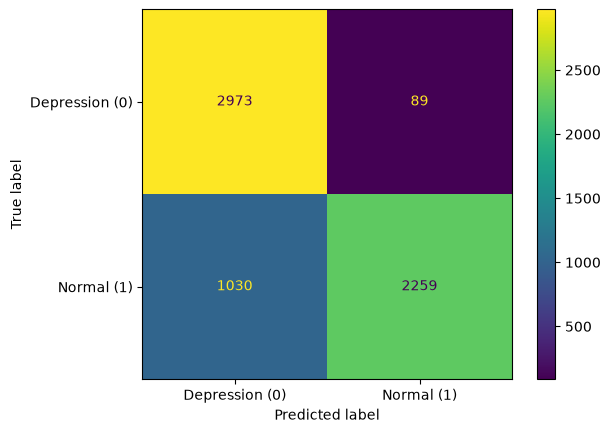

In [27]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test,
                                        display_labels=['Depression (0)', 'Normal (1)'])
plt.show()

In [28]:
def get_ratio(freqs, word):
    '''
    Input:
        freqs: dictionary containing the words

    Output: a dictionary with keys 'positive', 'negative', and 'ratio'.
        Example: {'positive': 10, 'negative': 20, 'ratio': 0.5}
    '''
    pos_neg_ratio = {'positive': 0, 'negative': 0, 'ratio': 0.0}

    # use lookup() to find positive counts for the word (denoted by the integer 1)
    pos_neg_ratio['positive'] = lookup(freqs, word, 1)

    # use lookup() to find negative counts for the word (denoted by integer 0)
    pos_neg_ratio['negative'] = lookup(freqs, word, 0)

    # calculate the ratio of positive to negative counts for the word
    pos_neg_ratio['ratio'] = (pos_neg_ratio["positive"] + 1) / (pos_neg_ratio["negative"] + 1)

    return pos_neg_ratio

In [29]:
get_ratio(freq, 'contento')

{'positive': 0, 'negative': 0, 'ratio': 1.0}

In [30]:
def get_words_by_threshold(freqs, label, threshold, get_ratio=get_ratio):
    '''
    Input:
        freqs: dictionary of words
        label: 1 for positive, 0 for negative
        threshold: ratio that will be used as the cutoff for including a word in the returned dictionary
    Output:
        word_list: dictionary containing the word and information on its positive count, negative count, and ratio of positive to negative counts.
        example of a key value pair:
        {'happi':
            {'positive': 10, 'negative': 20, 'ratio': 0.5}
        }
    '''
    word_list = {}


    for key in freqs.keys():
        word, _ = key

        # get the positive/negative ratio for a word
        pos_neg_ratio = get_ratio(freqs, word)

        # if the label is 1 and the ratio is greater than or equal to the threshold...
        if label == 1 and pos_neg_ratio['ratio'] >= threshold:

            # Add the pos_neg_ratio to the dictionary
            word_list[word] = pos_neg_ratio

        # If the label is 0 and the pos_neg_ratio is less than or equal to the threshold...
        elif label == 0 and pos_neg_ratio['ratio'] <= threshold:

            # Add the pos_neg_ratio to the dictionary
            word_list[word] = pos_neg_ratio

        # otherwise, do not include this word in the list (do nothing)


    return word_list

In [31]:
get_words_by_threshold(freq, label=0, threshold=0.05)

{'videojueg': {'positive': 5, 'negative': 279, 'ratio': 0.02142857142857143},
 'sient': {'positive': 466, 'negative': 10574, 'ratio': 0.044160756501182036},
 'sent': {'positive': 216, 'negative': 4673, 'ratio': 0.0464270432178006},
 'peor': {'positive': 45, 'negative': 1268, 'ratio': 0.036249014972419225},
 'simplement': {'positive': 191,
  'negative': 6105,
  'ratio': 0.03144448083851949},
 'acuest': {'positive': 1, 'negative': 78, 'ratio': 0.02531645569620253},
 '27': {'positive': 2, 'negative': 82, 'ratio': 0.03614457831325301},
 'sint': {'positive': 17, 'negative': 487, 'ratio': 0.036885245901639344},
 'depresion': {'positive': 34,
  'negative': 4873,
  'ratio': 0.0071809601969634795},
 'vid': {'positive': 300, 'negative': 8358, 'ratio': 0.03600909199665032},
 'confin': {'positive': 3, 'negative': 139, 'ratio': 0.02857142857142857},
 'avergonz': {'positive': 5, 'negative': 190, 'ratio': 0.031413612565445025},
 'autoestim': {'positive': 6, 'negative': 173, 'ratio': 0.040229885057471

In [32]:
get_words_by_threshold(freq, label=1, threshold=10)

{'©': {'positive': 53, 'negative': 0, 'ratio': 54.0},
 'ðÿ': {'positive': 261, 'negative': 0, 'ratio': 262.0},
 '˜': {'positive': 198, 'negative': 0, 'ratio': 199.0},
 'itun': {'positive': 11, 'negative': 0, 'ratio': 12.0},
 'nct': {'positive': 19, 'negative': 0, 'ratio': 20.0},
 '<url>': {'positive': 79, 'negative': 0, 'ratio': 80.0},
 '¥': {'positive': 66, 'negative': 0, 'ratio': 67.0},
 'picant': {'positive': 13, 'negative': 0, 'ratio': 14.0},
 'ta': {'positive': 9, 'negative': 0, 'ratio': 10.0},
 'â': {'positive': 197, 'negative': 0, 'ratio': 198.0},
 '™': {'positive': 150, 'negative': 0, 'ratio': 151.0},
 'ï': {'positive': 50, 'negative': 0, 'ratio': 51.0},
 '¸': {'positive': 63, 'negative': 0, 'ratio': 64.0},
 'ava': {'positive': 10, 'negative': 0, 'ratio': 11.0},
 'allah': {'positive': 52, 'negative': 3, 'ratio': 13.25},
 'seguidor': {'positive': 45, 'negative': 2, 'ratio': 15.333333333333334},
 'rt': {'positive': 53, 'negative': 0, 'ratio': 54.0},
 'jisung': {'positive': 10, 'n

## Palabras más discriminativas

Las palabras (raíces) con mayor y menor loglikelihood son las que más empujan la predicción hacia
`Normal` (positivo) o hacia `Depression` (negativo).

In [33]:
loglikelihood_s = pd.Series(loglikelihood)
pd.DataFrame({
    'Depression (más negativas)': loglikelihood_s.nsmallest(20).index,
    'loglik_dep': loglikelihood_s.nsmallest(20).values.round(2),
    'Normal (más positivas)': loglikelihood_s.nlargest(20).index,
    'loglik_normal': loglikelihood_s.nlargest(20).values.round(2),
})

,Depression (más negativas),loglik_dep,Normal (más positivas),loglik_normal
0,suic,-4.96,ðÿ,7.30
1,depresion,-3.20,˜,7.03
2,entumec,-3.13,â,7.02
3,cobard,-3.09,™,6.75
4,miser,-3.08,eid,6.36
5,colaps,-3.08,<url>,6.12
6,suicid,-3.05,¤,6.08
7,depres,-3.01,•,6.05
8,patet,-2.94,jyp,6.00
9,desesperanz,-2.91,¥,5.94
